# Demographic & Economic Analysis of Polish Regions
## 02 - Exploratory Data Analysis

### Objective

The goal of this notebook is to explore demographic and socioeconomic
differences between Polish voivodeships from 2010 to 2025.

The analysis focuses on:

- population change,
- migration balance,
- natural increase,
- unemployment,
- gross salary,
- population ageing.

The exploratory analysis will also prepare the data for testing relationships
between demographic trends and socioeconomic indicators.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [34]:
DATA_PATH = Path("../data/processed/polish_regions_analysis_ready.csv")

In [35]:
df = pd.read_csv(
    DATA_PATH,
    dtype={"unit_id": str}
)

df.head()

,unit_id,voivodeship,year,population,migration_balance,migration_balance_per_1000,natural_increase,natural_increase_per_1000,unemployment_rate,monthly_gross_salary_per_employee,population_65_plus,population_65_plus_share
0,011200000000,MAŁOPOLSKIE,2010,3336699,4408.0,1.32,7416,2.23,NaN,2997.0,453027,13.577101
1,011200000000,MAŁOPOLSKIE,2011,3346796,4300.0,1.29,5797,1.74,10.5,3148.0,462310,13.813510
2,011200000000,MAŁOPOLSKIE,2012,3354077,3577.0,1.07,4529,1.35,11.4,3352.0,473819,14.126658
3,011200000000,MAŁOPOLSKIE,2013,3360581,2824.0,0.84,4030,1.20,11.5,3431.0,487081,14.493952
4,011200000000,MAŁOPOLSKIE,2014,3368336,2947.0,0.88,4808,1.43,9.7,3573.0,501278,14.882066


## Initial data inspection

Before the exploratory analysis, the dataset is checked for its dimensions,
data types, missing values, duplicates and indicator coverage.

In [36]:
print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape:
(256, 12)

Columns:
['unit_id', 'voivodeship', 'year', 'population', 'migration_balance', 'migration_balance_per_1000', 'natural_increase', 'natural_increase_per_1000', 'unemployment_rate', 'monthly_gross_salary_per_employee', 'population_65_plus', 'population_65_plus_share']

Data types:
unit_id                                  str
voivodeship                              str
year                                   int64
population                             int64
migration_balance                    float64
migration_balance_per_1000           float64
natural_increase                       int64
natural_increase_per_1000            float64
unemployment_rate                    float64
monthly_gross_salary_per_employee    float64
population_65_plus                     int64
population_65_plus_share             float64
dtype: object


In [37]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicates:")
print(
    df.duplicated(
        subset=["unit_id", "year"]
    ).sum()
)

print("\nNumber of voivodeships:")
print(df["voivodeship"].nunique())

print("\nYear range:")
print(df["year"].min(), "-", df["year"].max())

Missing values:
unit_id                               0
voivodeship                           0
year                                  0
population                            0
migration_balance                    16
migration_balance_per_1000           16
natural_increase                      0
natural_increase_per_1000             0
unemployment_rate                    16
monthly_gross_salary_per_employee    16
population_65_plus                    0
population_65_plus_share              0
dtype: int64

Duplicates:
0

Number of voivodeships:
16

Year range:
2010 - 2025


In [38]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,256.0,2.017500e+03,4.618802e+00,2010.000000,2.013750e+03,2.017500e+03,2.021250e+03,2.025000e+03
population,256.0,2.386305e+06,1.239630e+06,923536.000000,1.325260e+06,2.127410e+06,3.022106e+06,5.517616e+06
migration_balance,240.0,3.400000e+00,4.520830e+03,-9318.000000,-2.427250e+03,-1.370000e+03,1.534250e+03,1.808400e+04
migration_balance_per_1000,240.0,-4.849167e-01,1.442096e+00,-3.310000,-1.445000e+00,-8.300000e-01,4.775000e-01,3.340000e+00
natural_increase,256.0,-3.816434e+03,6.495557e+03,-31416.000000,-7.326250e+03,-3.187500e+03,9.875000e+01,9.872000e+03
natural_increase_per_1000,256.0,-1.873789e+00,2.531392e+00,-8.120000,-3.642500e+00,-1.470000e+00,3.250000e-02,3.330000e+00
unemployment_rate,240.0,8.815833e+00,4.014534e+00,2.800000,5.575000e+00,8.100000e+00,1.115000e+01,2.160000e+01
monthly_gross_salary_per_employee,240.0,4.531083e+03,1.535832e+03,2448.000000,3.346250e+03,4.115000e+03,5.394250e+03,9.972000e+03
population_65_plus,256.0,4.095802e+05,2.234699e+05,119975.000000,2.277870e+05,3.626130e+05,5.158152e+05,1.092582e+06
population_65_plus_share,256.0,1.721488e+01,2.779542e+00,11.677817,1.497255e+01,1.713871e+01,1.925903e+01,2.384395e+01


In [39]:
print("Missing unemployment by year:")
print(
    df.loc[
        df["unemployment_rate"].isna(),
        "year"
    ].value_counts().sort_index()
)

print("\nMissing salary by year:")
print(
    df.loc[
        df["monthly_gross_salary_per_employee"].isna(),
        "year"
    ].value_counts().sort_index()
)

print("\nMissing migration balance by year:")
print(
    df.loc[
        df["migration_balance_per_1000"].isna(),
        "year"
    ].value_counts().sort_index()
)

Missing unemployment by year:
year
2010    16
Name: count, dtype: int64

Missing salary by year:
year
2025    16
Name: count, dtype: int64

Missing migration balance by year:
year
2015    16
Name: count, dtype: int64


## 1. Population change by voivodeship

The first part of the analysis examines how the population of each Polish
voivodeship changed between 2010 and 2025.

Both absolute and percentage changes are calculated to allow comparisons
between regions of different population sizes.

In [40]:
population_2010 = (
    df[df["year"] == 2010]
    [["unit_id", "voivodeship", "population"]]
    .rename(columns={"population": "population_2010"})
)

population_2025 = (
    df[df["year"] == 2025]
    [["unit_id", "voivodeship", "population"]]
    .rename(columns={"population": "population_2025"})
)

In [41]:
population_change = population_2010.merge(
    population_2025,
    on=["unit_id", "voivodeship"],
    how="inner",
    validate="one_to_one"
)

In [42]:
population_change["population_change"] = (
    population_change["population_2025"]
    - population_change["population_2010"]
)

population_change["population_change_pct"] = (
    population_change["population_change"]
    / population_change["population_2010"]
    * 100
)

In [43]:
population_change_sorted = (
    population_change
    .sort_values(
        "population_change_pct",
        ascending=False
    )
)

display(
    population_change_sorted[
        [
            "voivodeship",
            "population_2010",
            "population_2025",
            "population_change",
            "population_change_pct"
        ]
    ]
)

,voivodeship,population_2010,population_2025,population_change,population_change_pct
15,MAZOWIECKIE,5267072,5505857,238785,4.533543
8,POMORSKIE,2275494,2358409,82915,3.643824
0,MAŁOPOLSKIE,3336699,3429342,92643,2.776487
3,WIELKOPOLSKIE,3446745,3471302,24557,0.712469
5,DOLNOŚLĄSKIE,2917242,2857273,-59969,-2.055675
13,PODKARPACKIE,2127948,2053760,-74188,-3.486363
2,LUBUSKIE,1023215,963601,-59614,-5.826146
7,KUJAWSKO-POMORSKIE,2098711,1971891,-126820,-6.042757
14,PODLASKIE,1203448,1126679,-76769,-6.379087
4,ZACHODNIOPOMORSKIE,1723741,1612680,-111061,-6.443021


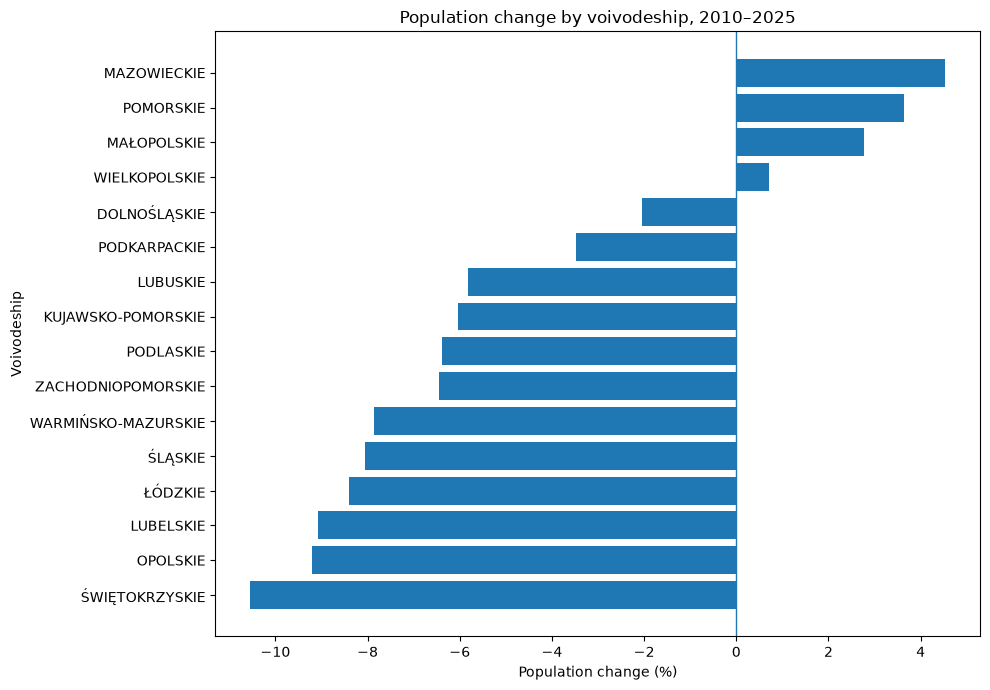

In [44]:
plot_data = population_change.sort_values(
    "population_change_pct"
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["voivodeship"],
    plot_data["population_change_pct"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Population change (%)")
plt.ylabel("Voivodeship")
plt.title("Population change by voivodeship, 2010–2025")

plt.tight_layout()
plt.show()

### Key observations

Between 2010 and 2025, population growth was concentrated in only a few
voivodeships. Mazowieckie recorded the largest percentage increase (+4.53%),
followed by Pomorskie (+3.64%) and Małopolskie (+2.78%).

In contrast, 12 out of 16 voivodeships experienced population decline.
The largest relative decrease occurred in Świętokrzyskie (-10.55%), while
Śląskie recorded the largest absolute population loss, with approximately
373 thousand fewer inhabitants in 2025 than in 2010.

These results indicate substantial regional differences in demographic
trends and motivate further analysis of migration, natural increase and
socioeconomic factors.

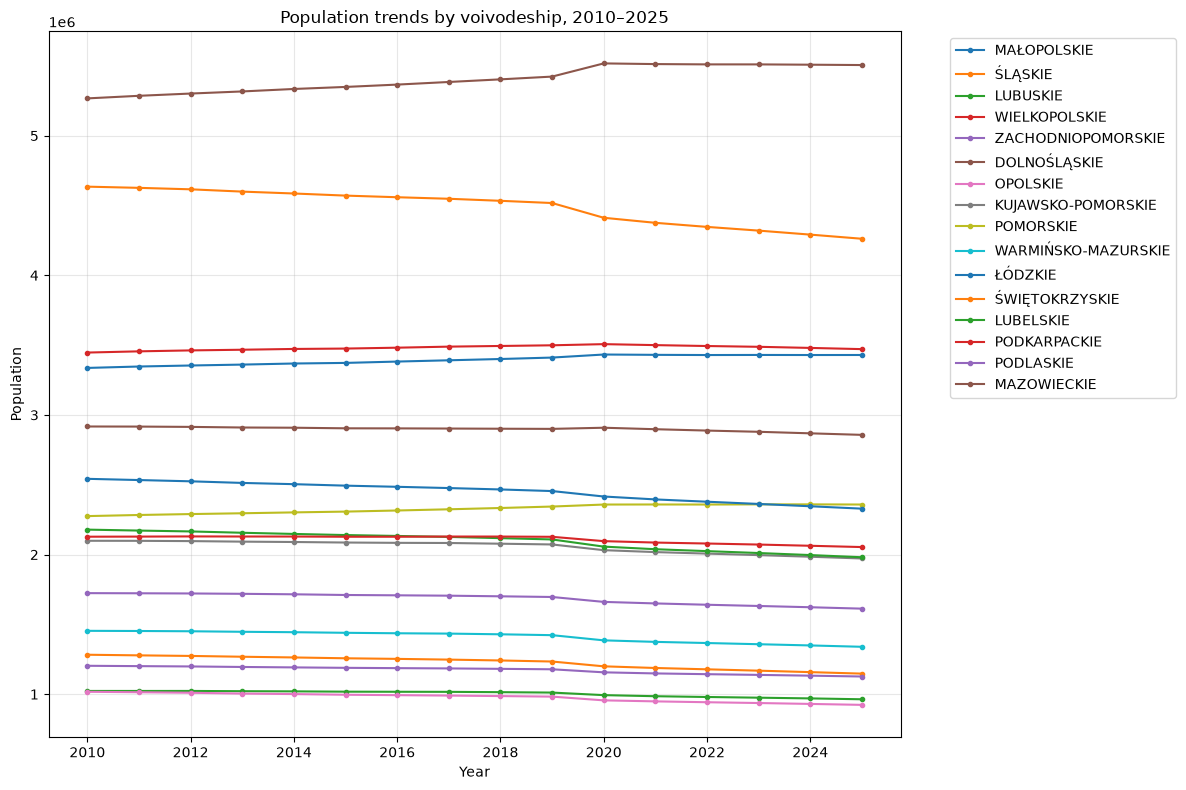

In [45]:
plt.figure(figsize=(12, 8))

for voivodeship in df["voivodeship"].unique():

    region_data = df[
        df["voivodeship"] == voivodeship
    ]

    plt.plot(
        region_data["year"],
        region_data["population"],
        marker="o",
        markersize=3,
        label=voivodeship
    )

plt.xlabel("Year")
plt.ylabel("Population")
plt.title("Population trends by voivodeship, 2010–2025")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
df["population_2010"] = (
    df.groupby("voivodeship")["population"]
    .transform("first")
)

df["population_index"] = (
    df["population"]
    / df["population_2010"]
    * 100
)

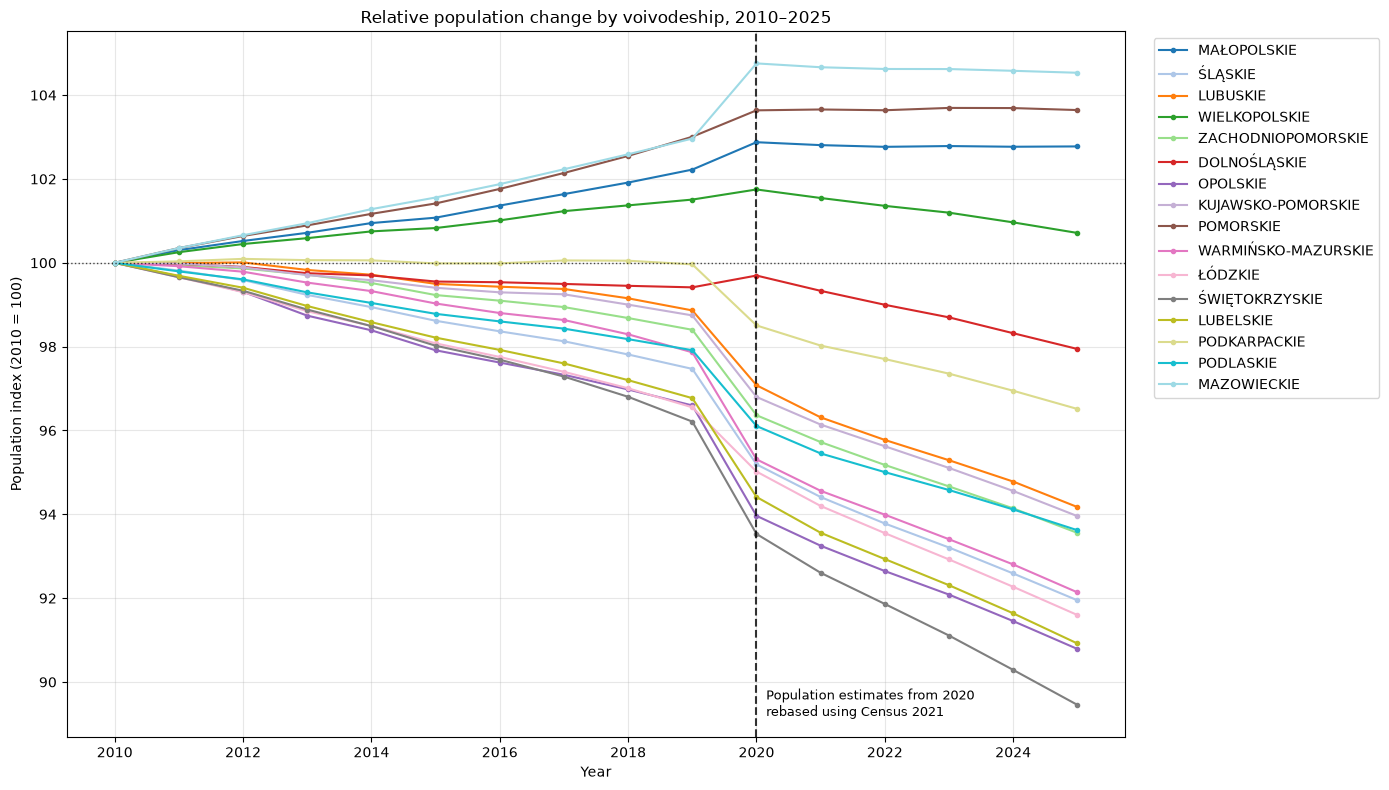

In [47]:
plt.figure(figsize=(14, 8))

voivodeships = df["voivodeship"].unique()

colors = plt.cm.tab20(
    np.linspace(0, 1, len(voivodeships))
)

for voivodeship, color in zip(voivodeships, colors):

    region_data = df[
        df["voivodeship"] == voivodeship
    ]

    plt.plot(
        region_data["year"],
        region_data["population_index"],
        marker="o",
        markersize=3,
        label=voivodeship,
        color=color
    )

plt.axhline(
    y=100,
    color="black",
    linestyle=":",
    linewidth=1,
    alpha=0.7
)

plt.axvline(
    x=2020,
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8
)

plt.text(
    2020.15,
    plt.ylim()[0] + 0.5,
    "Population estimates from 2020\nrebased using Census 2021",
    fontsize=9
)

plt.xlabel("Year")
plt.ylabel("Population index (2010 = 100)")
plt.title(
    "Relative population change by voivodeship, 2010–2025"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Methodological note

From 2020 onwards, Statistics Poland (GUS) uses the results of the 2021
National Population and Housing Census (NSP 2021) as the basis for population
balances. Population data for 2020 and 2021 were recalculated using the new
census benchmark.

Therefore, the visible break between 2019 and 2020 should not be interpreted
solely as an actual one-year population decline. Part of the change reflects
a revision of population estimates following the 2021 Census.

For this reason, year-to-year population changes around 2020 should be
interpreted with caution.

## 2. Natural increase and migration

Population change is closely related to two demographic processes:
natural increase and migration.

This section examines how these components differ between voivodeships
and how they may contribute to regional population trends.

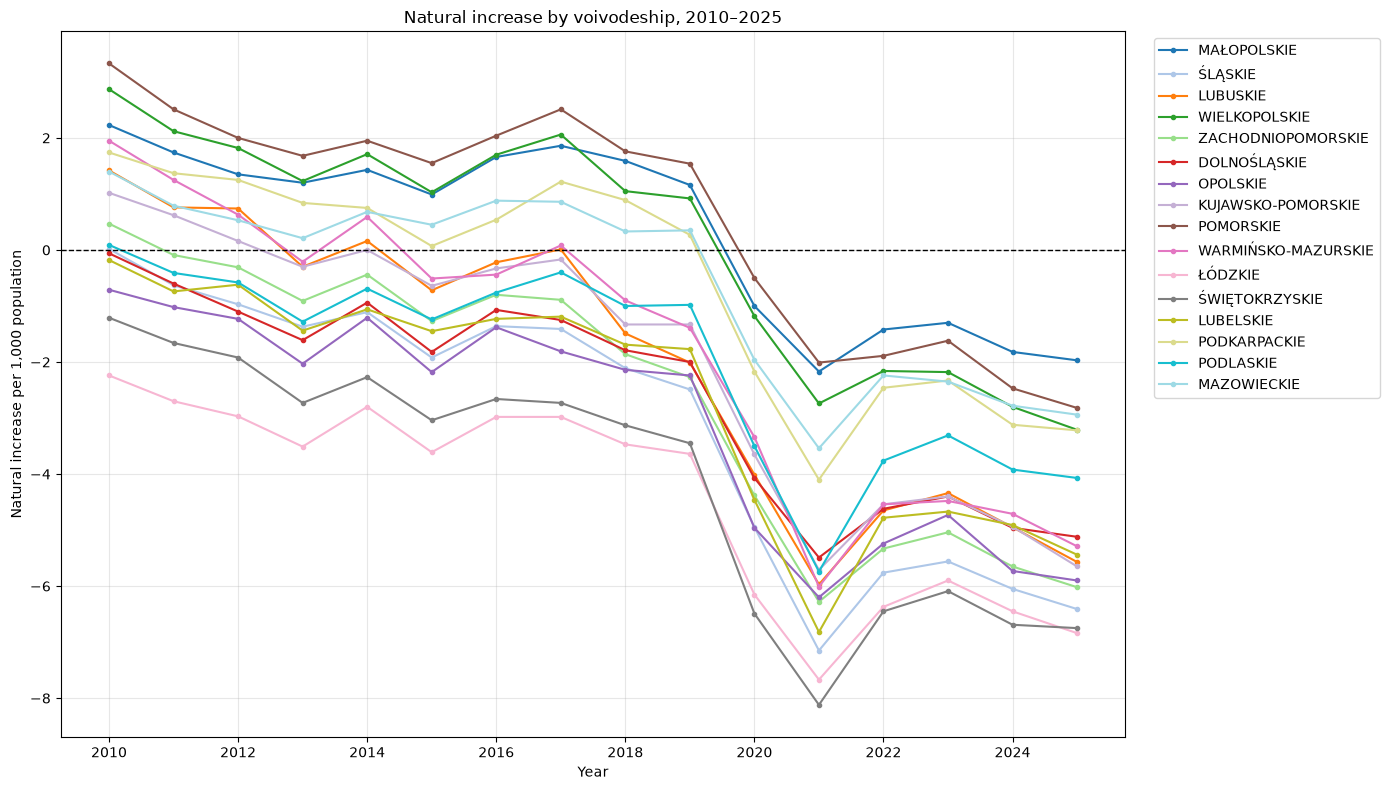

In [48]:
plt.figure(figsize=(14, 8))

voivodeships = df["voivodeship"].unique()

colors = plt.cm.tab20(
    np.linspace(0, 1, len(voivodeships))
)

for voivodeship, color in zip(voivodeships, colors):

    region_data = df[
        df["voivodeship"] == voivodeship
    ]

    plt.plot(
        region_data["year"],
        region_data["natural_increase_per_1000"],
        marker="o",
        markersize=3,
        label=voivodeship,
        color=color
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Year")
plt.ylabel("Natural increase per 1,000 population")
plt.title(
    "Natural increase by voivodeship, 2010–2025"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

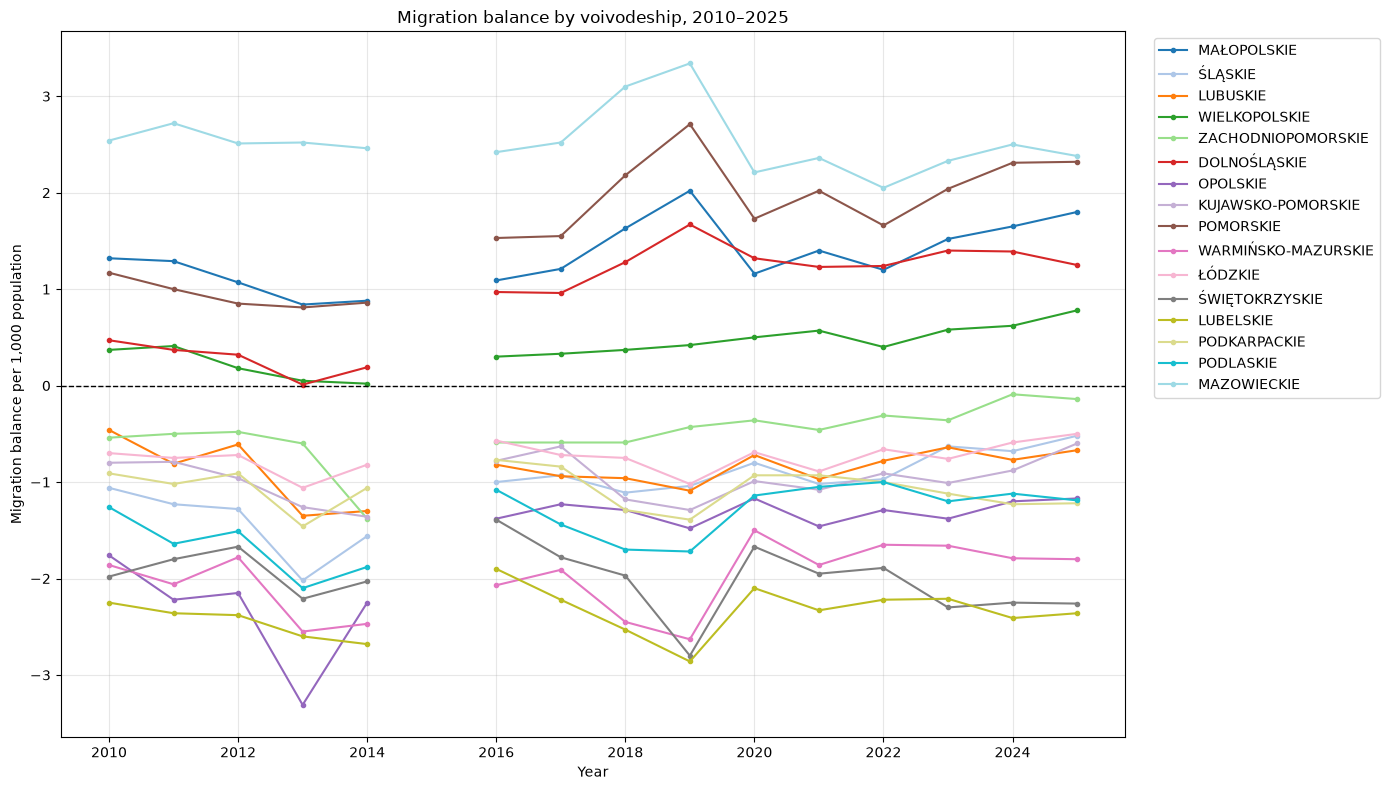

In [49]:
plt.figure(figsize=(14, 8))

for voivodeship, color in zip(voivodeships, colors):

    region_data = df[
        df["voivodeship"] == voivodeship
    ]

    plt.plot(
        region_data["year"],
        region_data["migration_balance_per_1000"],
        marker="o",
        markersize=3,
        label=voivodeship,
        color=color
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Year")
plt.ylabel("Migration balance per 1,000 population")
plt.title("Migration balance by voivodeship, 2010–2025")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Methodological note

Migration data for 2015 are treated as missing observations due to data
quality limitations in the underlying statistics.

The missing values were handled during the data collection and cleaning stage
and are therefore already represented as missing in the analysis-ready dataset.

As a result, 2015 is excluded from calculations involving migration indicators.

In [50]:
demography_2025 = (
    df[df["year"] == 2025]
    [
        [
            "voivodeship",
            "natural_increase_per_1000",
            "migration_balance_per_1000",
            "population_65_plus_share"
        ]
    ]
    .sort_values(
        "natural_increase_per_1000",
        ascending=False
    )
)

display(demography_2025)

,voivodeship,natural_increase_per_1000,migration_balance_per_1000,population_65_plus_share
15,MAŁOPOLSKIE,-1.97,1.80,19.205638
143,POMORSKIE,-2.82,2.32,19.404819
255,MAZOWIECKIE,-2.94,2.38,19.843995
63,WIELKOPOLSKIE,-3.21,0.78,19.632605
223,PODKARPACKIE,-3.22,-1.22,20.194911
239,PODLASKIE,-4.07,-1.19,21.223969
95,DOLNOŚLĄSKIE,-5.12,1.25,21.989008
159,WARMIŃSKO-MAZURSKIE,-5.29,-1.80,21.028997
207,LUBELSKIE,-5.44,-2.36,22.178575
47,LUBUSKIE,-5.57,-0.67,21.602614


### Regional comparison

To compare long-term demographic patterns between regions, average migration
balance and natural increase rates are calculated for each voivodeship.

These averages summarize the overall demographic conditions observed during
the analysed period and are compared with total population change between
2010 and 2025.

Migration data for 2015 are excluded from the calculation due to data quality
limitations described above.

In [51]:
demographic_summary = (
    df.groupby("voivodeship")
    .agg(
        avg_migration_per_1000=(
            "migration_balance_per_1000",
            "mean"
        ),
        avg_natural_increase_per_1000=(
            "natural_increase_per_1000",
            "mean"
        )
    )
    .reset_index()
)

demographic_summary = demographic_summary.merge(
    population_change[
        [
            "voivodeship",
            "population_change_pct"
        ]
    ],
    on="voivodeship",
    how="left",
    validate="one_to_one"
)

demographic_summary = demographic_summary.sort_values(
    "population_change_pct",
    ascending=False
)

display(demographic_summary)

,voivodeship,avg_migration_per_1000,avg_natural_increase_per_1000,population_change_pct
4,MAZOWIECKIE,2.530667,-0.583125,4.533543
9,POMORSKIE,1.649333,0.597500,3.643824
5,MAŁOPOLSKIE,1.338667,0.345625,2.776487
11,WIELKOPOLSKIE,0.393333,0.140000,0.712469
0,DOLNOŚLĄSKIE,0.938000,-2.556250,-2.055675
7,PODKARPACKIE,-1.072000,-0.528750,-3.486363
3,LUBUSKIE,-0.859333,-1.946250,-5.826146
1,KUJAWSKO-POMORSKIE,-0.968000,-1.949375,-6.042757
8,PODLASKIE,-1.402000,-1.971875,-6.379087
12,ZACHODNIOPOMORSKIE,-0.494667,-2.566875,-6.443021


### Key observations

The regional comparison reveals a clear relationship between migration patterns
and long-term population change.

The four voivodeships that recorded population growth between 2010 and 2025 —
Mazowieckie, Pomorskie, Małopolskie and Wielkopolskie — also had positive
average migration balances during the analysed period.

Regions experiencing the largest population declines generally combined
negative migration balances with negative natural increase. Świętokrzyskie,
for example, recorded both a strongly negative average migration balance
(-2.00 per 1,000 population) and a negative natural increase
(-4.09 per 1,000), alongside the largest population decline (-10.55%).

Dolnośląskie represents an interesting exception. Despite a positive average
migration balance (+0.94 per 1,000 population), its population decreased by
2.06%. This suggests that positive migration was not sufficient to offset
the negative natural increase observed in the region.

These descriptive patterns suggest that both migration and natural increase
may be associated with regional population change. Their relationships will
be examined more formally in the statistical analysis.

## 3. Population ageing

Population ageing is an important component of regional demographic change.

To examine differences in the age structure of Polish voivodeships, the share
of population aged 65 and over is analysed between 2010 and 2025.

The analysis focuses on both the overall trend in population ageing and
differences in the pace of ageing between regions.

In [52]:
ageing_2010 = (
    df[df["year"] == 2010]
    [["voivodeship", "population_65_plus_share"]]
    .rename(
        columns={
            "population_65_plus_share": "share_65_plus_2010"
        }
    )
)

ageing_2025 = (
    df[df["year"] == 2025]
    [["voivodeship", "population_65_plus_share"]]
    .rename(
        columns={
            "population_65_plus_share": "share_65_plus_2025"
        }
    )
)

ageing_change = ageing_2010.merge(
    ageing_2025,
    on="voivodeship",
    validate="one_to_one"
)

ageing_change["change_percentage_points"] = (
    ageing_change["share_65_plus_2025"]
    - ageing_change["share_65_plus_2010"]
)

ageing_change = ageing_change.sort_values(
    "change_percentage_points",
    ascending=False
)

display(ageing_change)

,voivodeship,share_65_plus_2010,share_65_plus_2025,change_percentage_points
4,ZACHODNIOPOMORSKIE,12.236235,22.604795,10.368559
2,LUBUSKIE,11.725297,21.602614,9.877316
9,WARMIŃSKO-MAZURSKIE,11.677817,21.028997,9.351181
11,ŚWIĘTOKRZYSKIE,14.822782,23.843953,9.021170
7,KUJAWSKO-POMORSKIE,12.543985,21.373342,8.829356
5,DOLNOŚLĄSKIE,13.340820,21.989008,8.648189
10,ŁÓDZKIE,14.931271,23.372473,8.441203
1,ŚLĄSKIE,14.220329,22.470735,8.250406
6,OPOLSKIE,14.163999,22.173364,8.009366
12,LUBELSKIE,14.379024,22.178575,7.799551


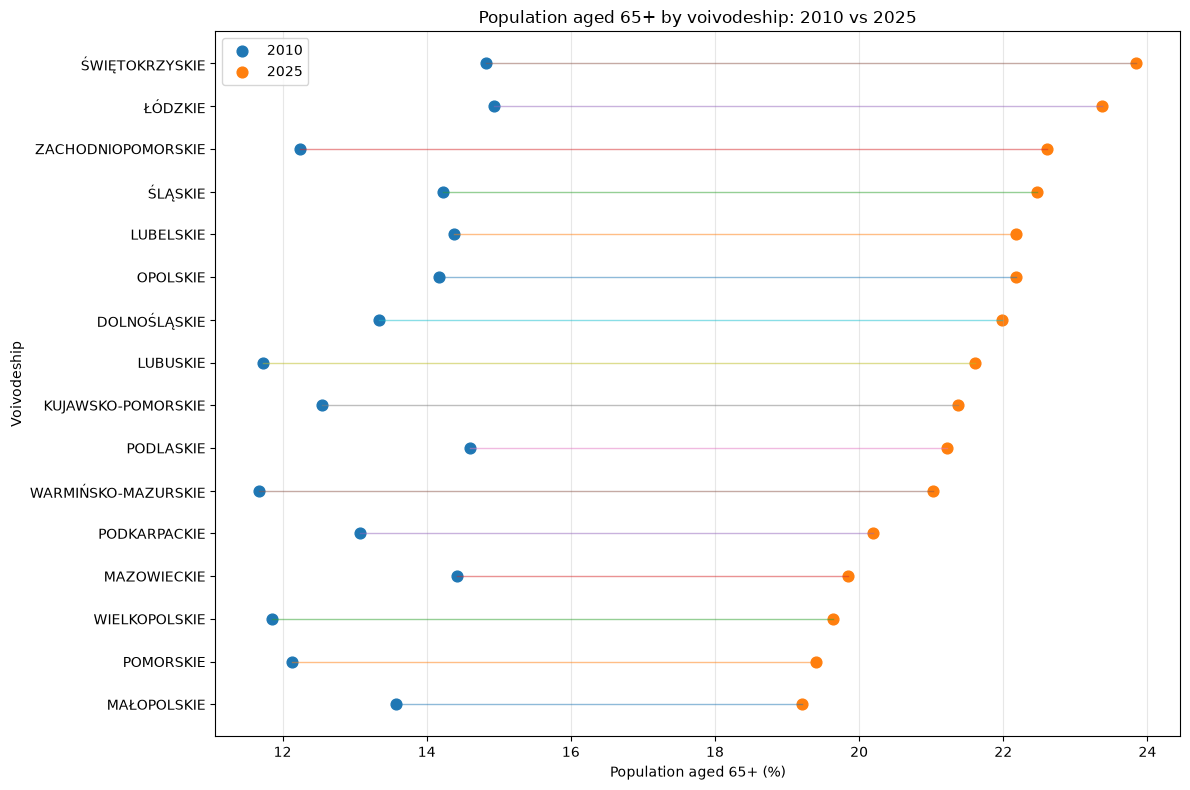

In [53]:
ageing_plot = ageing_change.sort_values(
    "share_65_plus_2025",
    ascending=True
)

y = np.arange(len(ageing_plot))

plt.figure(figsize=(12, 8))

plt.scatter(
    ageing_plot["share_65_plus_2010"],
    y,
    label="2010",
    s=60
)

plt.scatter(
    ageing_plot["share_65_plus_2025"],
    y,
    label="2025",
    s=60
)

for i in range(len(ageing_plot)):
    plt.plot(
        [
            ageing_plot.iloc[i]["share_65_plus_2010"],
            ageing_plot.iloc[i]["share_65_plus_2025"]
        ],
        [i, i],
        linewidth=1,
        alpha=0.5
    )

plt.yticks(
    y,
    ageing_plot["voivodeship"]
)

plt.xlabel("Population aged 65+ (%)")
plt.ylabel("Voivodeship")
plt.title("Population aged 65+ by voivodeship: 2010 vs 2025")

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Key observations

The share of the population aged 65 and over increased in all 16 voivodeships
between 2010 and 2025, indicating a widespread ageing of the population across
Polish regions.

The largest increase occurred in Zachodniopomorskie, where the share of the
65+ population increased by 10.37 percentage points. Large increases were also
observed in Lubuskie (+9.88 p.p.) and Warmińsko-Mazurskie (+9.35 p.p.).

By 2025, Świętokrzyskie had the highest share of population aged 65+
(23.84%), while Małopolskie had the lowest (19.21%).

The pace of population ageing differs substantially between regions. Some
voivodeships that had relatively young populations in 2010, such as Lubuskie
and Warmińsko-Mazurskie, experienced some of the largest increases in the
share of older residents.

These patterns suggest that population ageing may be related to broader
regional population decline. This relationship will be examined more formally
in the statistical analysis.

## 4. Socioeconomic conditions

Demographic differences between regions may be associated with socioeconomic
conditions.

This section explores two indicators available in the dataset: the registered
unemployment rate and monthly gross salary per employee.

The analysis first examines how these indicators changed over time and how
their levels differ between voivodeships.

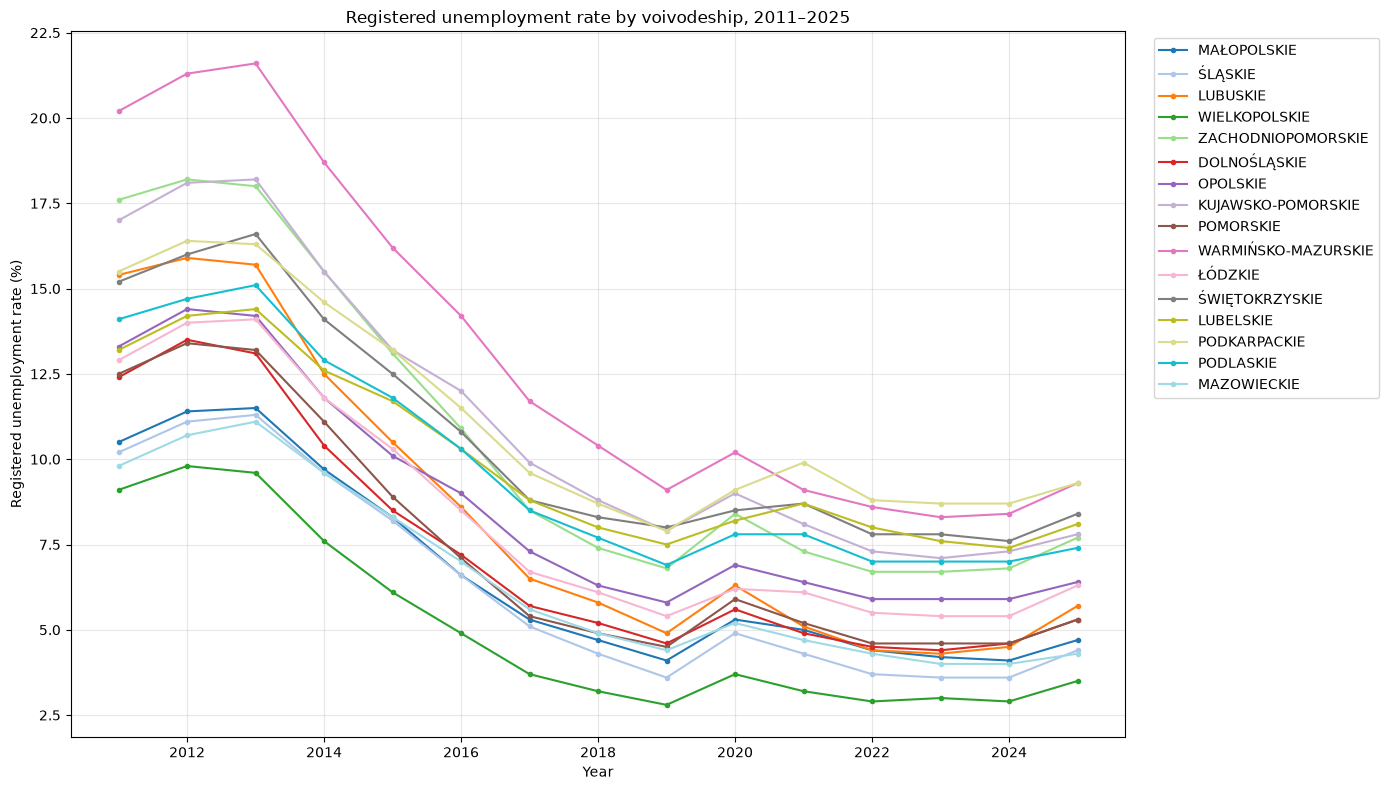

In [54]:
plt.figure(figsize=(14, 8))

for voivodeship, color in zip(voivodeships, colors):

    region_data = df[
        df["voivodeship"] == voivodeship
    ]

    plt.plot(
        region_data["year"],
        region_data["unemployment_rate"],
        marker="o",
        markersize=3,
        label=voivodeship,
        color=color
    )

plt.xlabel("Year")
plt.ylabel("Registered unemployment rate (%)")
plt.title("Registered unemployment rate by voivodeship, 2011–2025")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
unemployment_2011 = (
    df[df["year"] == 2011]
    [["voivodeship", "unemployment_rate"]]
    .rename(
        columns={
            "unemployment_rate": "unemployment_2011"
        }
    )
)

unemployment_2025 = (
    df[df["year"] == 2025]
    [["voivodeship", "unemployment_rate"]]
    .rename(
        columns={
            "unemployment_rate": "unemployment_2025"
        }
    )
)

unemployment_change = unemployment_2011.merge(
    unemployment_2025,
    on="voivodeship",
    validate="one_to_one"
)

unemployment_change["change_percentage_points"] = (
    unemployment_change["unemployment_2025"]
    - unemployment_change["unemployment_2011"]
)

unemployment_change = unemployment_change.sort_values(
    "unemployment_2025",
    ascending=False
)

display(unemployment_change)

,voivodeship,unemployment_2011,unemployment_2025,change_percentage_points
13,PODKARPACKIE,15.5,9.3,-6.2
9,WARMIŃSKO-MAZURSKIE,20.2,9.3,-10.9
11,ŚWIĘTOKRZYSKIE,15.2,8.4,-6.8
12,LUBELSKIE,13.2,8.1,-5.1
7,KUJAWSKO-POMORSKIE,17.0,7.8,-9.2
4,ZACHODNIOPOMORSKIE,17.6,7.7,-9.9
14,PODLASKIE,14.1,7.4,-6.7
6,OPOLSKIE,13.3,6.4,-6.9
10,ŁÓDZKIE,12.9,6.3,-6.6
2,LUBUSKIE,15.4,5.7,-9.7


### Key observations

Registered unemployment declined substantially across all Polish voivodeships
between 2011 and 2025.

The largest decrease occurred in Warmińsko-Mazurskie, where the unemployment
rate fell from 20.2% in 2011 to 9.3% in 2025, a decline of 10.9 percentage
points. Large decreases were also observed in Zachodniopomorskie (-9.9 p.p.)
and Lubuskie (-9.7 p.p.).

Despite the overall convergence in unemployment rates, substantial regional
differences remained in 2025. The lowest unemployment rate was recorded in
Wielkopolskie (3.5%), followed by Mazowieckie (4.3%) and Śląskie (4.4%).
The highest rates were observed in Podkarpackie and Warmińsko-Mazurskie
(9.3% each).

The time-series data also show a temporary increase in unemployment around
2020, interrupting the longer-term downward trend.

These regional differences provide a basis for examining whether labour market
conditions are associated with migration patterns in the statistical analysis.

### Monthly gross salary per employee

Regional differences in earnings are examined using monthly gross salary per
employee.

Salary data are available for 2010–2024. Therefore, comparisons in this
section use 2024 as the most recent available year.

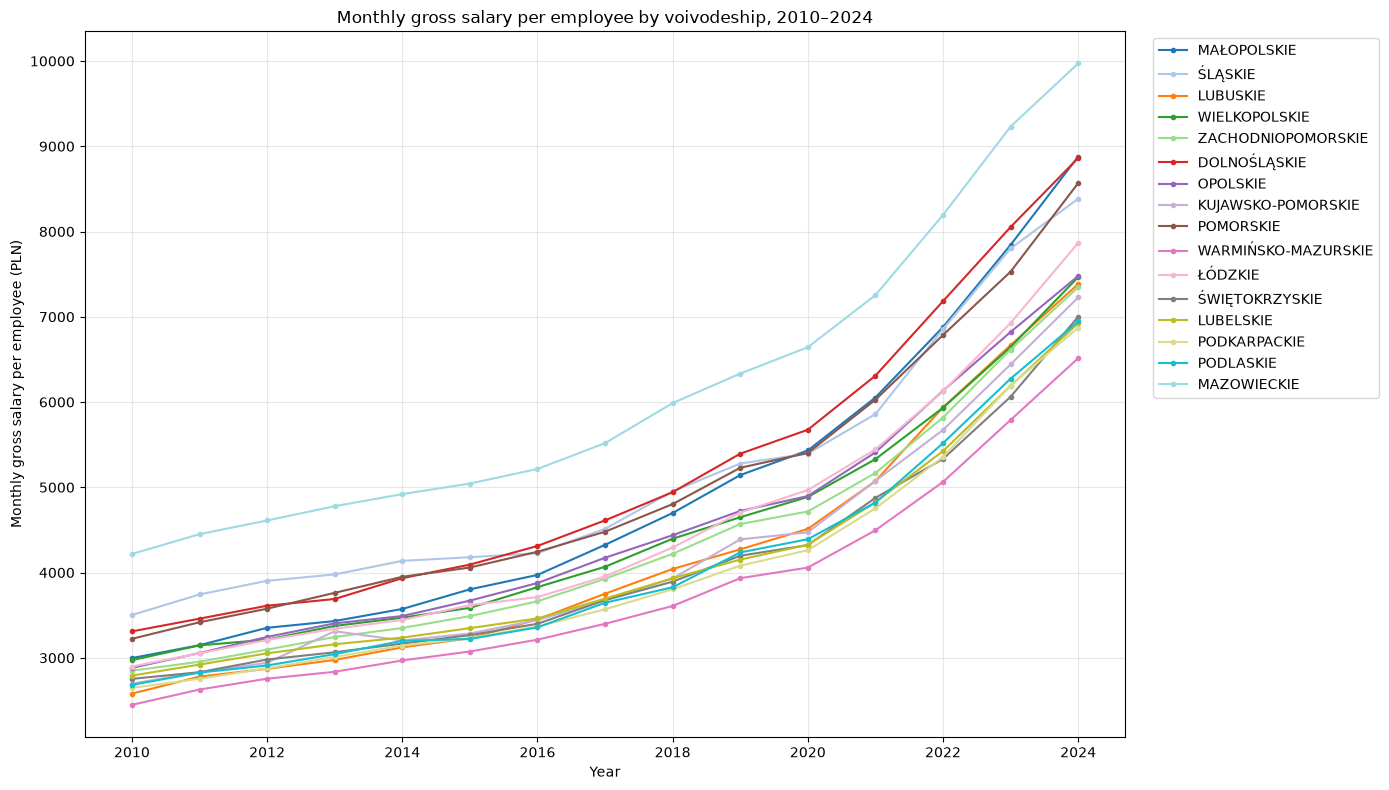

In [56]:
plt.figure(figsize=(14, 8))

for voivodeship, color in zip(voivodeships, colors):

    region_data = df[
        df["voivodeship"] == voivodeship
    ]

    plt.plot(
        region_data["year"],
        region_data["monthly_gross_salary_per_employee"],
        marker="o",
        markersize=3,
        label=voivodeship,
        color=color
    )

plt.xlabel("Year")
plt.ylabel("Monthly gross salary per employee (PLN)")
plt.title("Monthly gross salary per employee by voivodeship, 2010–2024")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
salary_2010 = (
    df[df["year"] == 2010]
    [["voivodeship", "monthly_gross_salary_per_employee"]]
    .rename(
        columns={
            "monthly_gross_salary_per_employee": "salary_2010"
        }
    )
)

salary_2024 = (
    df[df["year"] == 2024]
    [["voivodeship", "monthly_gross_salary_per_employee"]]
    .rename(
        columns={
            "monthly_gross_salary_per_employee": "salary_2024"
        }
    )
)

salary_change = salary_2010.merge(
    salary_2024,
    on="voivodeship",
    validate="one_to_one"
)

salary_change["salary_change"] = (
    salary_change["salary_2024"]
    - salary_change["salary_2010"]
)

salary_change["salary_change_pct"] = (
    salary_change["salary_change"]
    / salary_change["salary_2010"]
    * 100
)

salary_change = salary_change.sort_values(
    "salary_2024",
    ascending=False
)

display(salary_change)

,voivodeship,salary_2010,salary_2024,salary_change,salary_change_pct
15,MAZOWIECKIE,4218.0,9972.0,5754.0,136.415363
0,MAŁOPOLSKIE,2997.0,8879.0,5882.0,196.262930
5,DOLNOŚLĄSKIE,3310.0,8862.0,5552.0,167.734139
8,POMORSKIE,3223.0,8568.0,5345.0,165.839280
1,ŚLĄSKIE,3502.0,8385.0,4883.0,139.434609
10,ŁÓDZKIE,2898.0,7866.0,4968.0,171.428571
6,OPOLSKIE,2882.0,7479.0,4597.0,159.507287
3,WIELKOPOLSKIE,2973.0,7466.0,4493.0,151.126808
2,LUBUSKIE,2580.0,7384.0,4804.0,186.201550
4,ZACHODNIOPOMORSKIE,2849.0,7347.0,4498.0,157.879958


### Key observations

Monthly gross salary per employee increased substantially in all voivodeships
between 2010 and 2024.

In 2024, the highest value was recorded in Mazowieckie (9,972 PLN), followed
by Małopolskie (8,879 PLN) and Dolnośląskie (8,862 PLN). The lowest value was
observed in Warmińsko-Mazurskie (6,514 PLN).

Małopolskie recorded the largest percentage increase over the analysed period,
with monthly gross salary per employee rising from 2,997 PLN in 2010 to
8,879 PLN in 2024, an increase of approximately 196%.

Despite strong wage growth across all regions, substantial differences in
salary levels remained between voivodeships in 2024.

The values presented here are nominal and are not adjusted for inflation.
Therefore, the observed increases should not be interpreted as equivalent
increases in real purchasing power.

## 5. Relationships between demographic and socioeconomic indicators

After examining each indicator separately, the next step is to explore
relationships between demographic and socioeconomic conditions.

The analysis focuses on three relationships motivated by the initial research
hypotheses:

- unemployment rate and migration balance,
- monthly gross salary per employee and migration balance,
- population ageing and population change.

At this stage, the analysis is exploratory. Observed relationships should not
be interpreted as evidence of causality.

In [58]:
migration_unemployment = df[
    [
        "voivodeship",
        "year",
        "unemployment_rate",
        "migration_balance_per_1000"
    ]
].dropna()

print("Number of observations:", len(migration_unemployment))

Number of observations: 224


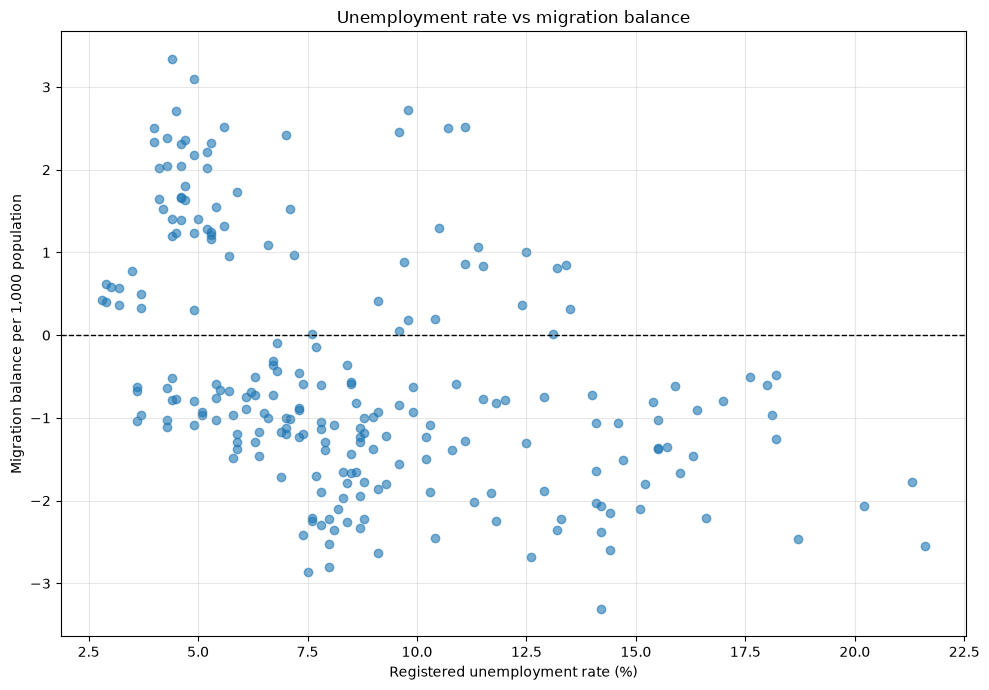

In [59]:
plt.figure(figsize=(10, 7))

plt.scatter(
    migration_unemployment["unemployment_rate"],
    migration_unemployment["migration_balance_per_1000"],
    alpha=0.6
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Registered unemployment rate (%)")
plt.ylabel("Migration balance per 1,000 population")
plt.title("Unemployment rate vs migration balance")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
migration_salary = df[
    [
        "voivodeship",
        "year",
        "monthly_gross_salary_per_employee",
        "migration_balance_per_1000"
    ]
].dropna()

print("Number of observations:", len(migration_salary))

Number of observations: 224


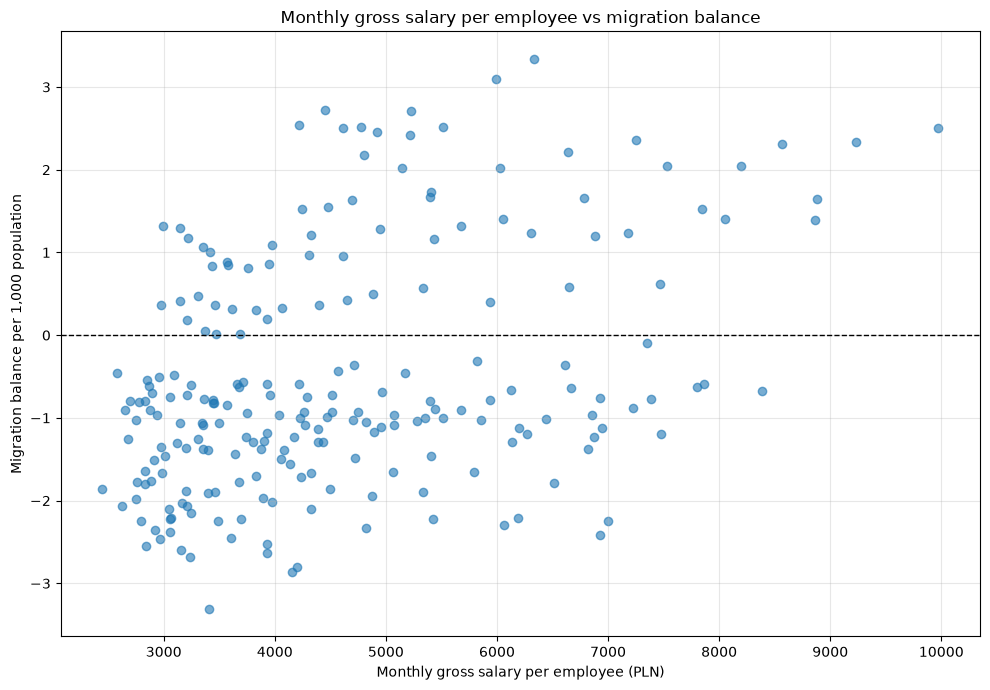

In [61]:
plt.figure(figsize=(10, 7))

plt.scatter(
    migration_salary["monthly_gross_salary_per_employee"],
    migration_salary["migration_balance_per_1000"],
    alpha=0.6
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Monthly gross salary per employee (PLN)")
plt.ylabel("Migration balance per 1,000 population")
plt.title("Monthly gross salary per employee vs migration balance")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
ageing_population = ageing_change[
    [
        "voivodeship",
        "change_percentage_points"
    ]
].merge(
    population_change[
        [
            "voivodeship",
            "population_change_pct"
        ]
    ],
    on="voivodeship",
    validate="one_to_one"
)

ageing_population = ageing_population.rename(
    columns={
        "change_percentage_points": "ageing_change_pp"
    }
)

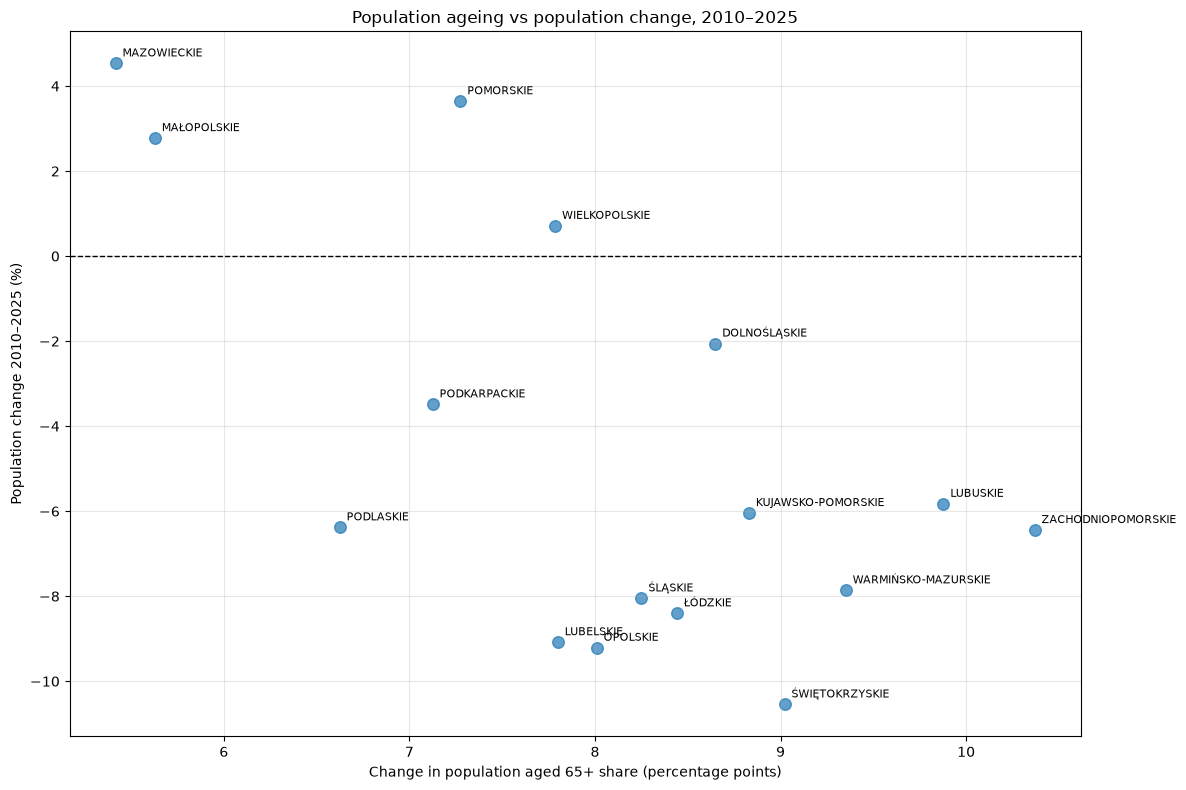

In [63]:
plt.figure(figsize=(12, 8))

plt.scatter(
    ageing_population["ageing_change_pp"],
    ageing_population["population_change_pct"],
    s=70,
    alpha=0.7
)

for _, row in ageing_population.iterrows():
    plt.annotate(
        row["voivodeship"],
        (
            row["ageing_change_pp"],
            row["population_change_pct"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Change in population aged 65+ share (percentage points)")
plt.ylabel("Population change 2010–2025 (%)")
plt.title("Population ageing vs population change, 2010–2025")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key observations

The exploratory analysis suggests several relationships between demographic
and socioeconomic indicators.

Observations with lower unemployment rates appear more frequently alongside
positive migration balances, while higher unemployment rates are generally
associated with negative migration balances. However, substantial variation
is visible across observations.

A positive relationship also appears between monthly gross salary per employee
and migration balance. Nevertheless, this relationship should be interpreted
with particular caution because nominal salaries increased substantially over
time across all regions.

The clearest visual pattern is observed between population ageing and long-term
population change. Voivodeships with smaller increases in the share of the
population aged 65+ generally experienced more favourable population trends,
while regions with stronger ageing tended to experience population decline.

These patterns are exploratory and do not demonstrate causality. Statistical
analysis is required to quantify the strength and direction of the observed
relationships.

## Conclusion

The exploratory analysis revealed substantial demographic and socioeconomic
differences between Polish voivodeships.

Most regions experienced population decline between 2010 and 2025, while
population ageing was observed across all voivodeships. Migration and natural
increase also varied considerably between regions.

Socioeconomic indicators showed substantial regional differences despite
general improvements in labour market conditions and increases in nominal
salary levels.

The exploratory relationships suggest that unemployment, salary levels and
population ageing may be associated with regional demographic trends.
These relationships are examined formally in the statistical analysis
notebook using Pearson and Spearman correlation coefficients.